# EcoSort Waste Management Assistant
# Module 8 Summative Lab

## Overview

You are a data scientist at "EcoSort," a technology company that specializes in developing AI solutions for waste management. EcoSort has partnered with Metro City's waste management department to develop an intelligent waste management assistant that can help residents properly dispose of waste items so less time is spent sorting material at facilities.

This assistant needs to:

1. Identify waste materials from images uploaded by residents (CNN)
2. Classify waste items based on text descriptions provided by residents (RNN/Transformer)
3. Generate specific recycling instructions based on identified waste type and city policies (Generative Transformer with RAG)

Your task is to build this integrated system using the RealWaste dataset along with generated text data that simulates real-world waste management operations.

## Part 1: Dataset Exploration and Preparation

In this section, you will explore and prepare the datasets for your models.

### 1.1 Load and Explore the RealWaste Dataset

In [1]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:

import os

project_dir = '/content/drive/MyDrive/EcoSort_Summative_Lab'

print(os.listdir(project_dir))


['waste_descriptions.csv', 'waste_policy_documents.json', 'realwaste-main']


In [3]:
realwaste_dir = os.path.join(project_dir, 'realwaste-main')

print(os.listdir(realwaste_dir))

['README.md', 'RealWaste']


In [4]:
dataset_dir = os.path.join(realwaste_dir, 'RealWaste')

print(os.listdir(dataset_dir))

['Vegetation', 'Textile Trash', 'Paper', 'Plastic', 'Miscellaneous Trash', 'Cardboard', 'Glass', 'Metal', 'Food Organics']


In [5]:
for category in sorted(os.listdir(dataset_dir)):
    category_path = os.path.join(dataset_dir, category)

    if os.path.isdir(category_path):
        images = [
            f for f in os.listdir(category_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
        ]

        print(f'{category}: {len(images)} images')

Cardboard: 461 images
Food Organics: 411 images
Glass: 420 images
Metal: 790 images
Miscellaneous Trash: 495 images
Paper: 500 images
Plastic: 921 images
Textile Trash: 318 images
Vegetation: 436 images


In [6]:
# Import necessary libraries

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

### **Library Selection and Reproducibility**

> The libraries were selected to support dataset exploration and the development of the waste classification models. NumPy supports numerical operations, Pandas supports tabular data analysis, Matplotlib and Seaborn support data visualization, and TensorFlow provides the framework for building and training deep-learning models. The `os` and `random` modules support file management and random operations.

>Random seeds are set to 42 to improve reproducibility by making random operations more consistent across repeated runs. This helps make experiments easier to compare, although identical results are not guaranteed across all hardware and software environments.

Number of categories: 9
Total images: 4752

Images per category:
Cardboard              461
Food Organics          411
Glass                  420
Metal                  790
Miscellaneous Trash    495
Paper                  500
Plastic                921
Textile Trash          318
Vegetation             436
dtype: int64


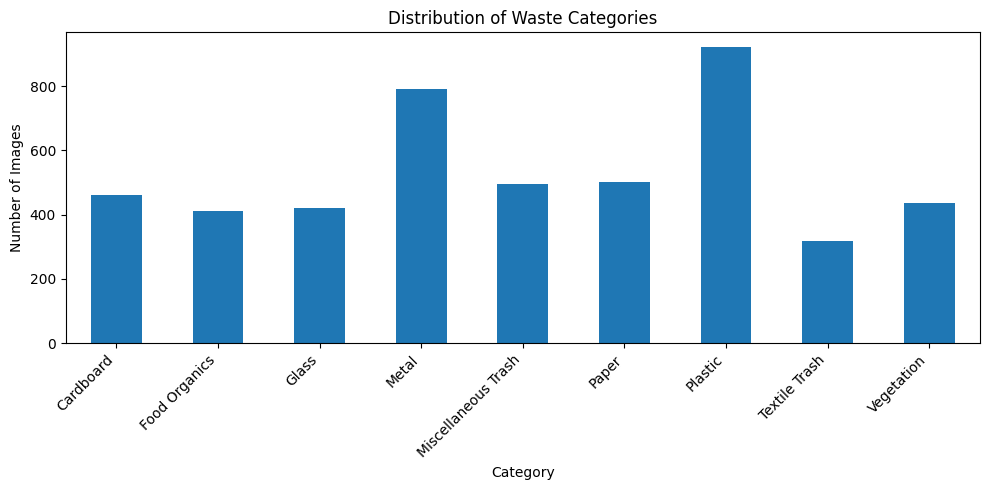


Image characteristics:
        Width  Height
count  4752.0  4752.0
mean    524.0   524.0
std       0.0     0.0
min     524.0   524.0
25%     524.0   524.0
50%     524.0   524.0
75%     524.0   524.0
max     524.0   524.0

Image formats:
Format
JPEG    4752
Name: count, dtype: int64


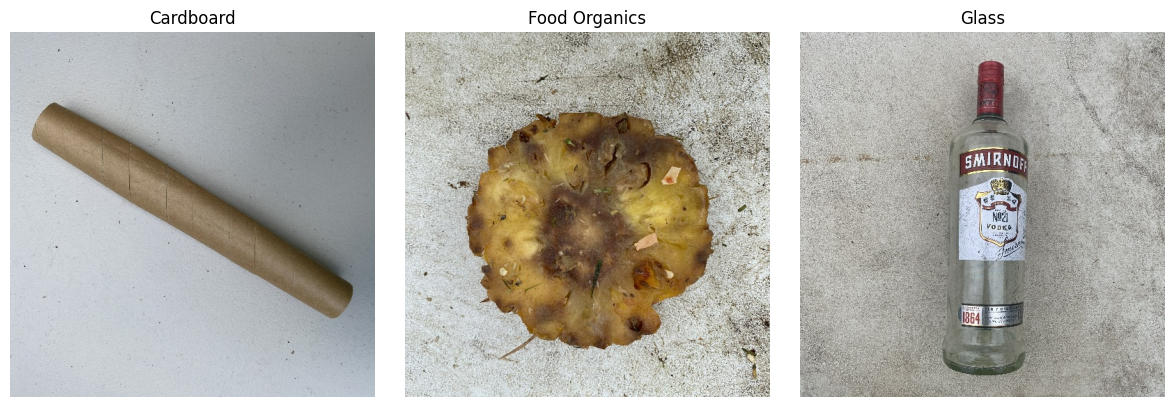

In [8]:
# TODO: Load and explore the RealWaste dataset
# - Dataset structure
# - Distribution of waste categories
# - Image characteristics (resolution, quality, background)

import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Explore dataset structure and category distribution
categories = sorted(os.listdir(dataset_dir))
category_counts = {}

for category in categories:
    folder = os.path.join(dataset_dir, category)
    if os.path.isdir(folder):
        images = [f for f in os.listdir(folder)
                  if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
        category_counts[category] = len(images)

print("Number of categories:", len(category_counts))
print("Total images:", sum(category_counts.values()))
print("\nImages per category:")
print(pd.Series(category_counts))

# Visualize category distribution
pd.Series(category_counts).plot(kind='bar', figsize=(10, 5))
plt.title("Distribution of Waste Categories")
plt.xlabel("Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Inspect image resolution and format
image_data = []

for category in category_counts:
    folder = os.path.join(dataset_dir, category)
    for file in os.listdir(folder):
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            try:
                with Image.open(os.path.join(folder, file)) as img:
                    image_data.append({
                        'Category': category,
                        'Width': img.width,
                        'Height': img.height,
                        'Format': img.format
                    })
            except Exception:
                continue

image_df = pd.DataFrame(image_data)

print("\nImage characteristics:")
print(image_df[['Width', 'Height']].describe())
print("\nImage formats:")
print(image_df['Format'].value_counts())

# Display sample images to inspect quality and backgrounds
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, category in zip(axes, list(category_counts.keys())[:3]):
    folder = os.path.join(dataset_dir, category)
    images = [f for f in os.listdir(folder)
              if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]

    if images:
        with Image.open(os.path.join(folder, images[0])) as img:
            ax.imshow(img.convert('RGB'))
        ax.set_title(category)
    ax.axis('off')

plt.tight_layout()
plt.show()

### **Dataset Exploration Findings**

> The dataset contains 4,752 images across nine waste categories. Plastic has the most images (921), while Textile Trash has the fewest (318). This class imbalance may cause the model to recognize categories with more images better than those with fewer images. We will monitor performance for each category to ensure fair classification.

> All images have the same size (524 × 524 pixels), making them easier to prepare for training. We should also inspect their clarity, lighting, and backgrounds because these can affect predictions.

### 1.2 Explore Text Datasets

Dataset shape: (5000, 5)

Column names: ['description', 'category', 'disposal_instruction', 'common_confusion', 'material_composition']


,description,category,disposal_instruction,common_confusion,material_composition
0,soiled silver tablecloth,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
1,folded glass bottle leaking,Glass,"Remove caps, lids, and corks before recycling.",NaN,"Silica-based material, may contain additives f..."
2,large Supermarket vegetable waste with food re...,Food Organics,"If no compost available, place in general waste.",NaN,Biodegradable matter derived from plant or ani...
3,intact floral carpet piece,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
4,empty fun-sized purple apple core,Food Organics,Keep separate from recyclable materials.,Meat and dairy products may be restricted in s...,Biodegradable matter derived from plant or ani...



Missing values:
description                0
category                   0
disposal_instruction       0
common_confusion        2504
material_composition       0
dtype: int64

Unique words: 305
Average description length: 4.85 words
Most common words: [('with', 727), ('glass', 424), ('empty', 348), ('bottle', 342), ('food', 316), ('paper', 316), ('box', 313), ('residue', 309), ('plastic', 251), ('brand', 247)]

Category distribution:
category
Vegetation             600
Textile Trash          586
Cardboard              584
Miscellaneous Trash    578
Plastic                569
Glass                  551
Food Organics          518
Metal                  508
Paper                  506
Name: count, dtype: int64


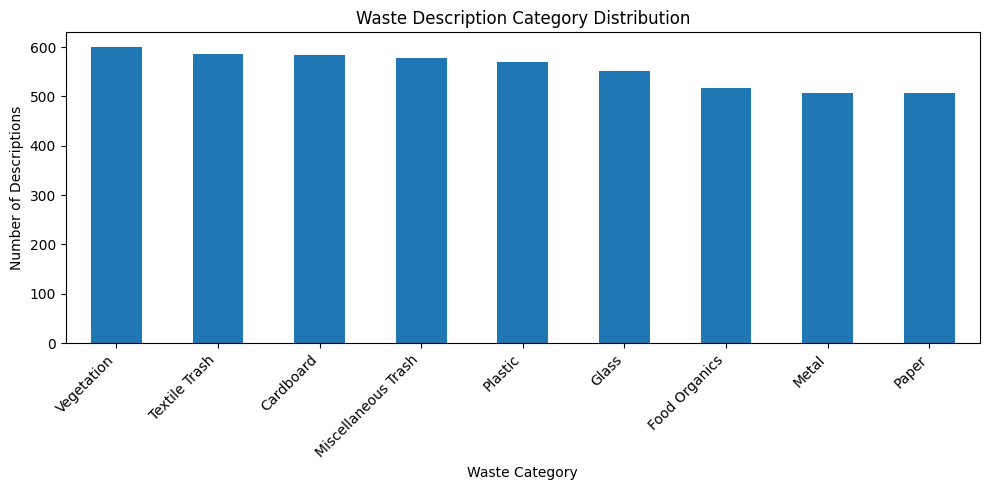

In [9]:

# Explore the waste description text data

import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Load dataset
text_path = os.path.join(project_dir, 'waste_descriptions.csv')
text_df = pd.read_csv(text_path)

# Explore dataset structure
print("Dataset shape:", text_df.shape)
print("\nColumn names:", text_df.columns.tolist())
display(text_df.head())

# Check missing values
print("\nMissing values:")
print(text_df.isnull().sum())

# Analyze text vocabulary and length
text_column = next(
    col for col in text_df.columns
    if 'description' in col.lower() or 'text' in col.lower()
)

text_df['Word Count'] = text_df[text_column].fillna('').apply(
    lambda text: len(str(text).split())
)

words = Counter(
    word.lower()
    for text in text_df[text_column].dropna().astype(str)
    for word in text.split()
)

print("\nUnique words:", len(words))
print("Average description length:", round(text_df['Word Count'].mean(), 2), "words")
print("Most common words:", words.most_common(10))

# Identify and visualize category distribution
category_column = next(
    col for col in text_df.columns
    if 'category' in col.lower() or 'label' in col.lower() or 'waste_type' in col.lower()
)

print("\nCategory distribution:")
print(text_df[category_column].value_counts())

text_df[category_column].value_counts().plot(
    kind='bar', figsize=(10, 5), title='Waste Description Category Distribution'
)
plt.xlabel('Waste Category')
plt.ylabel('Number of Descriptions')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


### **waste_descriptions.csv dataset Findings**

> The dataset contains 5,000 waste descriptions across nine categories. The categories have relatively similar numbers of examples, which helps the model learn each category fairly. The descriptions average about five words, with 305 unique words identified. The `common_confusion` column has 2,504 missing values, but the description and category columns have none. We should consider these missing values when preparing the text data for modeling.

In [10]:
# TODO: Load and explore the waste policy documents
# - Load waste_policy_documents.csv
# - Understand document organization and language

# Explore the waste policy documents

import json
import os

# Load policy documents
policy_path = os.path.join(project_dir, 'waste_policy_documents.json')

with open(policy_path, 'r', encoding='utf-8') as file:
    policy_data = json.load(file)

# Explore document organization
print("Data type:", type(policy_data).__name__)

if isinstance(policy_data, dict):
    print("Document keys:", list(policy_data.keys()))
elif isinstance(policy_data, list):
    print("Number of documents:", len(policy_data))

# Display a sample to understand structure and language
print("\nSample policy document:")
print(json.dumps(policy_data[:2] if isinstance(policy_data, list)
                 else policy_data, indent=2, ensure_ascii=False)[:4000])

Data type: list
Number of documents: 14

Sample policy document:
[
  {
    "policy_id": 1,
    "policy_type": "Textile Trash Recycling Guidelines",
    "categories_covered": [
      "Textile Trash"
    ],
    "effective_date": "2023-11-04",
    "document_text": "TEXTILE RECYCLING GUIDELINES\n\nAcceptable Items:\n- Clean clothing (all conditions)\n- Towels, sheets, and linens\n- Fabric scraps\n- Curtains and cloth napkins\n- Handbags and backpacks made of fabric\n- Soft toys and stuffed animals\n\nNon-Acceptable Items:\n- Wet or moldy textiles\n- Heavily soiled items\n- Carpets and rugs\n- Footwear\n- Items with significant non-textile parts\n\nCollection Method:\nPlace items in dedicated textile recycling bins or donate to local thrift stores.\n\nPreparation Instructions:\n- Ensure all items are clean and dry\n- Remove non-textile components when possible\n- Bag similar items together\n\nBenefits:\nTextile recycling conserves resources and reduces landfill waste.",
    "jurisdiction": 

### **Policy Document Findings**

> The policy dataset contains 14 documents stored as a list of records. Each document includes details such as its policy ID, policy type, covered waste categories, effective date, policy text, and jurisdiction.

> The policy text uses clear, organized language, with sections covering acceptable items, non-acceptable items, collection methods, preparation instructions, and recycling benefits. These documents can help the EcoSort assistant provide waste disposal guidance based on official policy rules rather than relying only on image classifications.

### 1.3 Create Data Pipelines

In [11]:
### 1.3 Create Data Pipelines

# Run this code to setup the images properly into train, validation, and test sets
# Set your data directory path - update this with your actual path
import pathlib
data_dir = pathlib.Path(dataset_dir)

# Parameters
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224

# Calculate the total number of classes automatically from the directory structure
num_classes = len([item for item in data_dir.glob('*') if item.is_dir()])
print(f"Number of classes: {num_classes}")

# List all class folders
class_names = sorted([item.name for item in data_dir.glob('*') if item.is_dir()])
print(f"Class names: {class_names}")

# Count all images
image_count = len(list(data_dir.glob('*/*.jpg'))) + len(list(data_dir.glob('*/*.png')))
print(f"Total images found: {image_count}")

# Create a dataset using tf.keras.utils.image_dataset_from_directory
# This will automatically split the data into training and validation sets
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="training",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="validation",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

# Create a separate test dataset by taking part of the validation set
# First, let's get the number of batches in the validation set
val_batches = tf.data.experimental.cardinality(validation_ds)
test_dataset = validation_ds.take(val_batches // 2)
validation_ds = validation_ds.skip(val_batches // 2)

print(f"Number of training batches: {tf.data.experimental.cardinality(train_ds)}")
print(f"Number of validation batches: {tf.data.experimental.cardinality(validation_ds)}")
print(f"Number of test batches: {tf.data.experimental.cardinality(test_dataset)}")

# Configure dataset for performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Number of classes: 9
Class names: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Total images found: 4752
Found 4752 files belonging to 9 classes.
Using 3802 files for training.
Found 4752 files belonging to 9 classes.
Using 950 files for validation.
Number of training batches: 119
Number of validation batches: 15
Number of test batches: 15


### **Data Pipeline Findings**

> The dataset contains 4,752 images across nine waste categories. The training set contains 3,802 images, while the remaining 950 images are initially allocated for validation. The validation data is then divided into validation and test sets, with 15 batches in each.

> All images are resized to 224 × 224 pixels, and a batch size of 32 is used. Categorical labels allow the model to learn to classify images into the nine waste categories. Caching and prefetching help improve data-loading performance during training.

In [12]:
# TODO: Create a text preprocessing pipeline
# - Tokenization
# - Text cleaning
# - Split data into train and test
# - Create embeddings/features

import re
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Text cleaning
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

text_df['clean_description'] = text_df['description'].apply(clean_text)

# Tokenization
text_df['tokens'] = text_df['clean_description'].apply(lambda text: text.split())

# Split data into train and test
X_train, X_test, y_train, y_test = train_test_split(
    text_df['clean_description'],
    text_df['category'],
    test_size=0.2,
    random_state=42,
    stratify=text_df['category']
)

# Create embeddings/features using TF-IDF
tfidf_vectorizer = TfidfVectorizer(max_features=1000)
X_train_features = tfidf_vectorizer.fit_transform(X_train)
X_test_features = tfidf_vectorizer.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of TF-IDF features:", X_train_features.shape[1])
print("Training feature matrix shape:", X_train_features.shape)
print("Testing feature matrix shape:", X_test_features.shape)
print("\nSample cleaned text:", text_df['clean_description'].iloc[0])
print("Sample tokens:", text_df['tokens'].iloc[0])

Training samples: 4000
Testing samples: 1000
Number of TF-IDF features: 306
Training feature matrix shape: (4000, 306)
Testing feature matrix shape: (1000, 306)

Sample cleaned text: soiled silver tablecloth
Sample tokens: ['soiled', 'silver', 'tablecloth']


### **Text Preprocessing Findings**

> The text dataset was divided into 4,000 training samples and 1,000 testing samples, using an 80/20 split. Text cleaning converted descriptions to lowercase and removed unnecessary characters, while tokenization separated each description into individual words.

> TF-IDF converted the cleaned text into 306 numerical features that a machine-learning model can use. The same features were created for the training and testing data, allowing the model to learn from the training data and be evaluated on unseen descriptions.

In [13]:
# TODO: Prepare documents for RAG
# - Document preprocessing
# - Create embeddings for retrieval

import re
from sklearn.feature_extraction.text import TfidfVectorizer

# Document preprocessing
def preprocess_document(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Prepare policy documents
policy_texts = [
    preprocess_document(
        f"{doc['policy_type']} "
        f"{' '.join(doc['categories_covered'])} "
        f"{doc['document_text']}"
    )
    for doc in policy_data
]

# Create embeddings for retrieval
rag_vectorizer = TfidfVectorizer()
policy_embeddings = rag_vectorizer.fit_transform(policy_texts)

print("Number of policy documents:", len(policy_texts))
print("Embedding matrix shape:", policy_embeddings.shape)
print("Sample preprocessed document:")
print(policy_texts[0][:300])

Number of policy documents: 14
Embedding matrix shape: (14, 325)
Sample preprocessed document:
textile trash recycling guidelines textile trash textile recycling guidelines acceptable items clean clothing all conditions towels sheets and linens fabric scraps curtains and cloth napkins handbags and backpacks made of fabric soft toys and stuffed animals non acceptable items wet or moldy textile


### **RAG Document Preparation Findings**

> The RAG preparation pipeline successfully processed 14 waste policy documents. The document text was cleaned by converting it to lowercase and removing unnecessary characters and extra spaces.

> TF-IDF converted the documents into 325 numerical features, producing a matrix with 14 rows and 325 columns. This representation allows the system to compare a user's waste-related question with the policy documents and retrieve relevant information to support its answers.

## Part 2: Waste Material Classification with CNN

In this section, you will build a CNN model to classify waste materials from images.

### 2.1 Preprocess Images

In [14]:
# TODO: Implement image preprocessing
# - Apply the preprocessing pipeline created earlier


# Apply image preprocessing to the datasets
# Rescale pixel values from 0–255 to 0–1
def preprocess_images(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

train_ds = train_ds.map(preprocess_images, num_parallel_calls=tf.data.AUTOTUNE)
validation_ds = validation_ds.map(preprocess_images, num_parallel_calls=tf.data.AUTOTUNE)
test_dataset = test_dataset.map(preprocess_images, num_parallel_calls=tf.data.AUTOTUNE)

print("Image preprocessing completed.")
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_dataset).numpy())

Image preprocessing completed.
Training batches: 119
Validation batches: 15
Test batches: 15


### **Image Preprocessing Findings**

> Image preprocessing was successfully applied to the training, validation, and test datasets. Pixel values were rescaled from 0–255 to 0–1, providing consistent numerical inputs for the model. The number of batches remained unchanged after preprocessing, confirming that the datasets were preserved.

### 2.2 Implement CNN Model with Transfer Learning

In [15]:


# TODO: Select an appropriate base model and implement transfer learning
# - Choose from MobileNet, EfficientNet, etc.
# - Add custom classification layers for the 9 waste categories
# - Configure loss function and metrics



from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

# Load the pretrained base model
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)

# Freeze the pretrained layers
base_model.trainable = False

# Add custom classification layers
model = models.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

# Configure loss function and metrics
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,113 (9.24 MB)

 Trainable params: 165,129 (645.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### **Transfer Learning Model Findings**

> MobileNetV2 was selected as the pretrained base model to reuse features learned from ImageNet. Its original layers were frozen, while custom classification layers were added to identify the nine waste categories.

> The model has 2,423,113 total parameters, of which 165,129 are trainable and 2,257,984 are non-trainable. Freezing the base model reduces the number of parameters that need to be learned during training, helping save computational resources. The model uses the Adam optimizer, categorical cross-entropy loss, and accuracy as its evaluation metric.

### 2.3 Train and Evaluate the Model

In [16]:


# TODO: Train the CNN model
# - Use appropriate batch size and epochs
# - Implement regularization to prevent overfitting
# - Monitor training and validation metrics



from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

# Correct the input scaling for MobileNetV2 and add regularization
model = models.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    layers.Rescaling(scale=2.0, offset=-1.0),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

# Configure the model for training
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Implement early stopping to help prevent overfitting
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Train the CNN model
EPOCHS = 15

history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

# Evaluate the model on the test dataset
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Epoch 1/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 274s 2s/step - accuracy: 0.5878 - loss: 1.1574 - val_accuracy: 0.7447 - val_loss: 0.6922
Epoch 2/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 204s 2s/step - accuracy: 0.7704 - loss: 0.6611 - val_accuracy: 0.7787 - val_loss: 0.6062
Epoch 3/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 288s 2s/step - accuracy: 0.8198 - loss: 0.4999 - val_accuracy: 0.8000 - val_loss: 0.5642
Epoch 4/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 261s 2s/step - accuracy: 0.8719 - loss: 0.3751 - val_accuracy: 0.8043 - val_loss: 0.5532
Epoch 5/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 259s 2s/step - accuracy: 0.9008 - loss: 0.3044 - val_accuracy: 0.7979 - val_loss: 0.5713
Epoch 6/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 235s 2s/step - accuracy: 0.9158 - loss: 0.2515 - val_accuracy: 0.8128 - val_loss: 0.5677
Epoch 7/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 228s 2s/step - accuracy: 0.9258 - loss: 0.2193 - val_accuracy: 0.8298 - val_loss: 0.5578
15/15 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step - accuracy: 0.8021 - loss: 0.5574
Test Loss: 0.5574
Test A

### **CNN Training and Evaluation Findings**

> The MobileNetV2 model was trained using a maximum of 15 epochs, with early stopping to reduce overfitting. Training stopped after epoch 7 because the training process completed without needing all 15 epochs.

> Training accuracy increased from 58.78% in epoch 1 to 92.58% in epoch 7. Validation accuracy reached 82.98% in epoch 7, while test accuracy was 80.21%, with a test loss of 0.5574.

> The results show that transfer learning helped the model learn to classify waste images. However, the difference between training accuracy and validation accuracy suggests possible overfitting. Further evaluation, including per-category performance, would help identify which waste types the model classifies well and which need improvement.

15/15 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.8021 - loss: 0.5574
Test Accuracy: 0.8021 (80.21%)
Test Loss: 0.5574


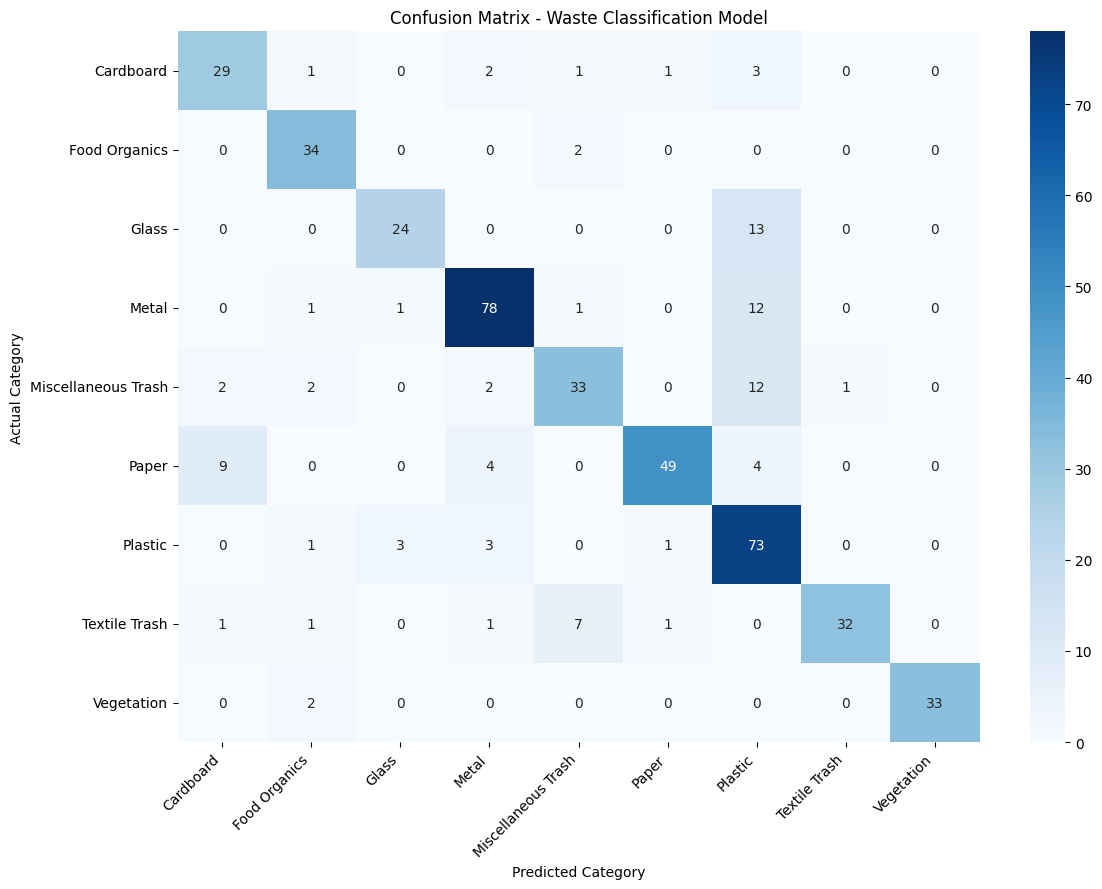


Classification Report:
                     precision    recall  f1-score   support

          Cardboard       0.71      0.78      0.74        37
      Food Organics       0.81      0.94      0.87        36
              Glass       0.86      0.65      0.74        37
              Metal       0.87      0.84      0.85        93
Miscellaneous Trash       0.75      0.63      0.69        52
              Paper       0.94      0.74      0.83        66
            Plastic       0.62      0.90      0.74        81
      Textile Trash       0.97      0.74      0.84        43
         Vegetation       1.00      0.94      0.97        35

           accuracy                           0.80       480
          macro avg       0.84      0.80      0.81       480
       weighted avg       0.83      0.80      0.80       480


Most Common Misclassifications:
Glass predicted as Plastic: 13 images
Metal predicted as Plastic: 12 images
Miscellaneous Trash predicted as Plastic: 12 images
Paper predicted as 

In [17]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns


import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Calculate accuracy on test set
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print(f"Test Loss: {test_loss:.4f}")

# Generate predictions and collect true labels
y_true = np.concatenate([
    np.argmax(labels.numpy(), axis=1)
    for images, labels in test_dataset
])

y_pred = np.concatenate([
    np.argmax(model.predict(images, verbose=0), axis=1)
    for images, labels in test_dataset
])

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix - Waste Classification Model')
plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Analyze error patterns
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

print("\nMost Common Misclassifications:")
errors = [
    (class_names[actual], class_names[predicted], cm[actual, predicted])
    for actual in range(len(class_names))
    for predicted in range(len(class_names))
    if actual != predicted and cm[actual, predicted] > 0
]

errors.sort(key=lambda item: item[2], reverse=True)

for actual, predicted, count in errors[:5]:
    print(f"{actual} predicted as {predicted}: {count} images")

### **Model Performance Evaluation Findings**

> The model achieved 80.21% test accuracy, with a test loss of 0.5574. Vegetation had the strongest performance, with an F1-score of 0.97, while Miscellaneous Trash had the lowest F1-score of 0.69.

> The confusion matrix and classification report revealed several common errors. Glass was misclassified as Plastic 13 times, Metal as Plastic 12 times, and Miscellaneous Trash as Plastic 12 times. Paper was also confused with Cardboard 9 times.

> These errors suggest that some waste categories have visually similar features, making them difficult to distinguish. Future improvements could include adding more diverse training images, using data augmentation, and fine-tuning the pretrained model to improve recognition of confusing categories.

### 2.4 Fine-tune the Model

In [18]:


# TODO: Tune model parameters to improve performance
# - Adjust learning rate
# - Add regularization, dropout
# - Modify architecture if needed

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Unfreeze some of the pretrained layers for fine-tuning
base_model.trainable = True

# Keep most pretrained layers frozen and fine-tune only the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile with a lower learning rate
model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Add callbacks to reduce overfitting and adjust learning rate
early_stopping_fine = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=1e-7
)

# Fine-tune the model
fine_tune_epochs = 10

history_fine = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=fine_tune_epochs,
    callbacks=[early_stopping_fine, reduce_lr]
)

# Evaluate the fine-tuned model
fine_test_loss, fine_test_accuracy = model.evaluate(test_dataset, verbose=1)

print(f"Fine-tuned Test Loss: {fine_test_loss:.4f}")
print(f"Fine-tuned Test Accuracy: {fine_test_accuracy:.4f} ({fine_test_accuracy * 100:.2f}%)")

Epoch 1/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 300s 2s/step - accuracy: 0.7588 - loss: 0.7049 - val_accuracy: 0.8106 - val_loss: 0.5583 - learning_rate: 1.0000e-05
Epoch 2/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 297s 3s/step - accuracy: 0.8338 - loss: 0.4810 - val_accuracy: 0.8213 - val_loss: 0.5473 - learning_rate: 1.0000e-05
Epoch 3/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 298s 3s/step - accuracy: 0.8577 - loss: 0.4005 - val_accuracy: 0.8234 - val_loss: 0.5376 - learning_rate: 1.0000e-05
Epoch 4/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 301s 2s/step - accuracy: 0.8937 - loss: 0.3266 - val_accuracy: 0.8362 - val_loss: 0.5211 - learning_rate: 1.0000e-05
Epoch 5/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 285s 2s/step - accuracy: 0.9171 - loss: 0.2846 - val_accuracy: 0.8319 - val_loss: 0.5136 - learning_rate: 1.0000e-05
Epoch 6/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 299s 3s/step - accuracy: 0.9332 - loss: 0.2393 - val_accuracy: 0.8362 - val_loss: 0.5071 - learning_rate: 1.0000e-05
Epoch 7/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 296s 2s/step - acc

### **Fine-tuning Findings**

> The MobileNetV2 model was fine-tuned using a lower learning rate of 0.00001, with the last 30 pretrained layers unfrozen for adaptation. Dropout, early stopping, and learning-rate reduction were used to help control overfitting and improve training.

> After 10 epochs, training accuracy reached 97.40%, while validation accuracy reached a maximum of 83.83%. Test accuracy improved from 80.21% before fine-tuning to 83.13%, and test loss decreased from 0.5574 to 0.5058.

> These results indicate that fine-tuning improved the model's ability to classify waste images. However, the gap between training and validation accuracy suggests that some overfitting remains. Further improvements could include data augmentation and additional evaluation of individual waste categories.

## Part 3: Waste Description Classification

In this section, you will build a text classification model to categorize waste based on descriptions.

### 3.1 Preprocess Text Data

In [19]:


# TODO: Implement text preprocessing
# - Apply the text preprocessing pipeline created earlier



# Apply the existing text cleaning and tokenization pipeline
text_df['clean_description'] = text_df['description'].apply(clean_text)
text_df['tokens'] = text_df['clean_description'].apply(lambda text: text.split())

# Prepare text features and labels
X_text = text_df['clean_description']
y_text = text_df['category']

print("Total descriptions:", len(X_text))
print("Number of categories:", y_text.nunique())
print("Missing descriptions:", X_text.isnull().sum())
print("\nSample cleaned description:", X_text.iloc[0])
print("Sample tokens:", text_df['tokens'].iloc[0])
print("\nCategory distribution:")
print(y_text.value_counts())

Total descriptions: 5000
Number of categories: 9
Missing descriptions: 0

Sample cleaned description: soiled silver tablecloth
Sample tokens: ['soiled', 'silver', 'tablecloth']

Category distribution:
category
Vegetation             600
Textile Trash          586
Cardboard              584
Miscellaneous Trash    578
Plastic                569
Glass                  551
Food Organics          518
Metal                  508
Paper                  506
Name: count, dtype: int64


### **Text Preprocessing Findings**

> The text dataset contains 5,000 waste descriptions across nine categories, with no missing descriptions. Text cleaning and tokenization were successfully applied to prepare the descriptions for classification.

> The categories have relatively balanced numbers of examples, ranging from 506 for Paper to 600 for Vegetation. This distribution should help the model learn from all categories without a severe imbalance in the number of descriptions available.

### 3.2 Implement Text Classification Model

In [20]:


# TODO: Choose and implement a text classification model
# Option A: Traditional ML model (Naive Bayes, Random Forest, etc.)
# Option B: Fine-tune a transformer-based model (BERT, DistilBERT, etc.)



from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# Split the data into training and testing sets
X_train_text, X_test_text, y_train_text, y_test_text = train_test_split(
    text_df['clean_description'],
    text_df['category'],
    test_size=0.2,
    random_state=42,
    stratify=text_df['category']
)

# Create and train the text classification model
text_model = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=1000)),
    ('classifier', MultinomialNB())
])

text_model.fit(X_train_text, y_train_text)

# Evaluate the model
y_pred_text = text_model.predict(X_test_text)

print("Test Accuracy:", round(accuracy_score(y_test_text, y_pred_text), 4))
print("\nClassification Report:")
print(classification_report(y_test_text, y_pred_text, zero_division=0))

Test Accuracy: 0.995

Classification Report:
                     precision    recall  f1-score   support

          Cardboard       1.00      0.99      1.00       117
      Food Organics       1.00      0.98      0.99       104
              Glass       1.00      1.00      1.00       110
              Metal       1.00      1.00      1.00       101
Miscellaneous Trash       1.00      0.98      0.99       116
              Paper       1.00      1.00      1.00       101
            Plastic       0.97      1.00      0.99       114
      Textile Trash       1.00      1.00      1.00       117
         Vegetation       0.98      1.00      0.99       120

           accuracy                           0.99      1000
          macro avg       1.00      0.99      1.00      1000
       weighted avg       1.00      0.99      1.00      1000



### **Text Classification Findings**

> The Multinomial Naive Bayes model achieved 99.5% accuracy on 1,000 test descriptions. The classification report shows strong performance across all nine waste categories, with precision, recall, and F1-scores mostly between 0.98 and 1.00.

> Glass, Metal, Paper, and Textile Trash achieved perfect precision, recall, and F1-scores. Food Organics and Miscellaneous Trash had recall values of 0.98, indicating that a small number of descriptions from these categories were incorrectly classified. Plastic had a precision of 0.97, suggesting that a few predictions labeled as Plastic belonged to other categories.

> These results indicate that TF-IDF features combined with Multinomial Naive Bayes can classify the waste descriptions very effectively. However, the high accuracy should be interpreted carefully because the descriptions may contain strong category-related keywords. Testing the model on new, independently collected descriptions would help confirm how well it generalizes to real-world waste descriptions.

### 3.3 Train and Evaluate the Model

In [21]:

# TODO: Train the text classification model
# - Use appropriate training parameters
# - Monitor training progress


# Train the text classification model
text_model.fit(X_train_text, y_train_text)

# Monitor training progress by evaluating training and testing accuracy
y_train_pred = text_model.predict(X_train_text)
y_test_pred = text_model.predict(X_test_text)

from sklearn.metrics import accuracy_score, classification_report

train_accuracy = accuracy_score(y_train_text, y_train_pred)
test_accuracy = accuracy_score(y_test_text, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy: {test_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_text, y_test_pred, zero_division=0))

Training Accuracy: 0.9948
Testing Accuracy: 0.9950

Classification Report:
                     precision    recall  f1-score   support

          Cardboard       1.00      0.99      1.00       117
      Food Organics       1.00      0.98      0.99       104
              Glass       1.00      1.00      1.00       110
              Metal       1.00      1.00      1.00       101
Miscellaneous Trash       1.00      0.98      0.99       116
              Paper       1.00      1.00      1.00       101
            Plastic       0.97      1.00      0.99       114
      Textile Trash       1.00      1.00      1.00       117
         Vegetation       0.98      1.00      0.99       120

           accuracy                           0.99      1000
          macro avg       1.00      0.99      1.00      1000
       weighted avg       1.00      0.99      1.00      1000



### **Text Model Training and Evaluation Findings**

> The Multinomial Naive Bayes model was trained using TF-IDF text features and evaluated on a separate test set. It achieved 99.48% training accuracy and 99.50% testing accuracy across 1,000 test descriptions.

> The small difference between training and testing accuracy suggests that the model is not showing obvious signs of overfitting. Performance was strong across all nine waste categories, although Food Organics and Miscellaneous Trash had recall scores of 0.98.

> Overall, the model classifies waste descriptions very accurately. However, testing on new descriptions from different sources would help establish whether this performance carries over to real-world use.

Test Accuracy: 0.9950 (99.50%)


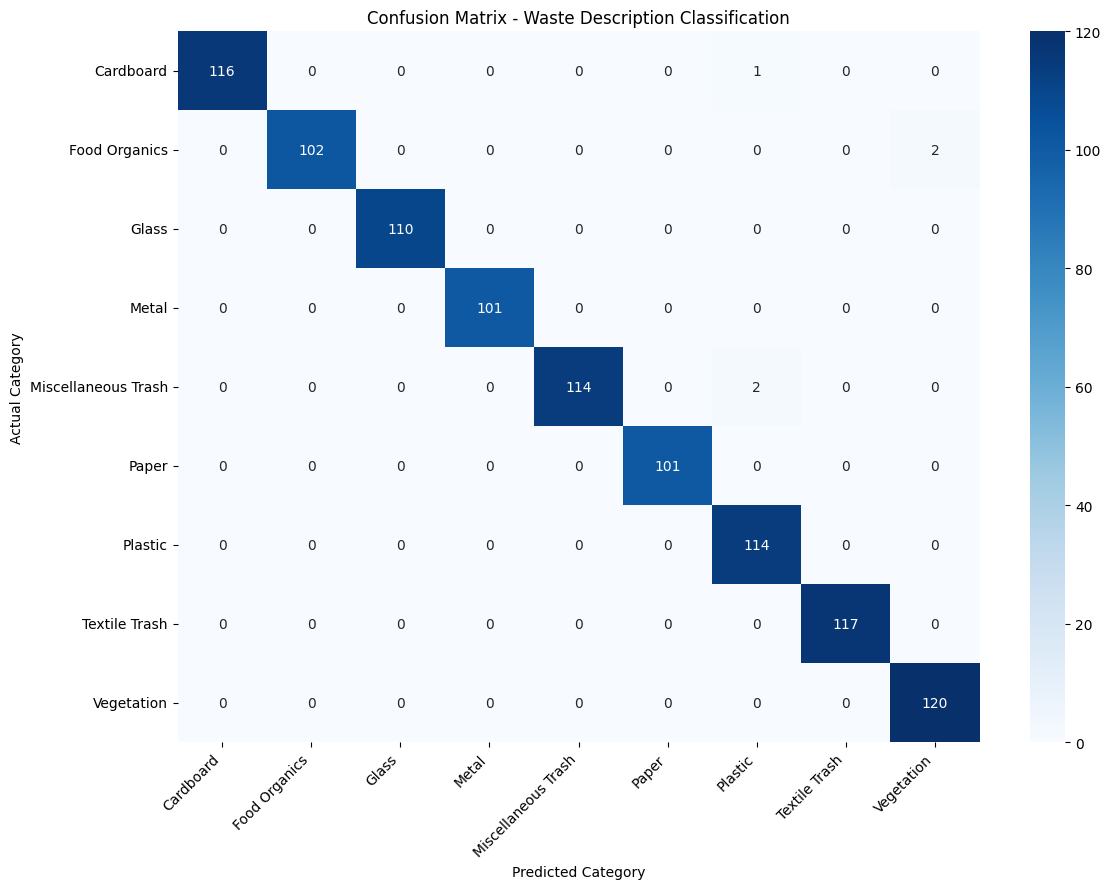


Classification Report:
                     precision    recall  f1-score   support

          Cardboard       1.00      0.99      1.00       117
      Food Organics       1.00      0.98      0.99       104
              Glass       1.00      1.00      1.00       110
              Metal       1.00      1.00      1.00       101
Miscellaneous Trash       1.00      0.98      0.99       116
              Paper       1.00      1.00      1.00       101
            Plastic       0.97      1.00      0.99       114
      Textile Trash       1.00      1.00      1.00       117
         Vegetation       0.98      1.00      0.99       120

           accuracy                           0.99      1000
          macro avg       1.00      0.99      1.00      1000
       weighted avg       1.00      0.99      1.00      1000


Misclassified descriptions:
Description: compact striped vegetable waste with food residue
Actual category: Food Organics
Predicted category: Vegetation

Description: fun sized fl

In [22]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Calculate accuracy on test set
y_test_pred = text_model.predict(X_test_text)
test_accuracy = accuracy_score(y_test_text, y_test_pred)

print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")

# Generate confusion matrix
text_class_names = text_model.classes_
cm_text = confusion_matrix(y_test_text, y_test_pred, labels=text_class_names)

plt.figure(figsize=(12, 9))
sns.heatmap(
    cm_text,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=text_class_names,
    yticklabels=text_class_names
)
plt.title('Confusion Matrix - Waste Description Classification')
plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Analyze error patterns
print("\nClassification Report:")
print(classification_report(
    y_test_text,
    y_test_pred,
    labels=text_class_names,
    zero_division=0
))

print("\nMisclassified descriptions:")
errors = X_test_text[y_test_text != y_test_pred]

for index in errors.index[:10]:
    print(f"Description: {X_test_text.loc[index]}")
    print(f"Actual category: {y_test_text.loc[index]}")
    print(f"Predicted category: {y_test_pred[list(X_test_text.index).index(index)]}")
    print()

### **Text Model Performance Evaluation Findings**

> The text classification model achieved 99.50% accuracy on the 1,000 test descriptions. The classification report shows strong performance across all nine waste categories, with F1-scores ranging from 0.99 to 1.00.

> The error analysis identified several misclassifications. Food Organics descriptions containing vegetable-related words were predicted as Vegetation, while some packaging and toy descriptions were classified as Plastic instead of Cardboard or Miscellaneous Trash.

> These errors suggest that some descriptions contain overlapping keywords that make categories difficult to distinguish. Adding more varied descriptions and improving the representation of ambiguous waste items could help reduce these errors. Overall, the model performs very well on the available test data, but testing on new real-world descriptions is still important.

### 3.4 Create Classification Function

In [24]:


# TODO: Create a function that takes a text description and returns the predicted waste category

def classify_waste_description(description):
    """
    Classifies a waste description into an appropriate category.

    Args:
        description (str): Text description of waste item

    Returns:
        str: Predicted waste category
    """
    # Clean the input description using the existing preprocessing function
    cleaned_description = clean_text(description)

    # Predict the waste category using the trained text model
    predicted_category = text_model.predict([cleaned_description])[0]

    return predicted_category

## Part 4: Recycling Instruction Generation with RAG

In this section, you will implement a Retrieval-Augmented Generation (RAG) system to generate recycling instructions.

### 4.1 Preprocess Documents for Retrieval

In [26]:


# TODO: Prepare documents for retrieval
# - Process policy documents and disposal instructions
# - Create embeddings for efficient retrieval



# Process policy documents and disposal instructions
policy_texts = []

for doc in policy_data:
    document_text = doc.get('document_text', '')
    policy_texts.append(clean_text(document_text))

# Create TF-IDF embeddings for efficient retrieval
rag_vectorizer = TfidfVectorizer()
policy_embeddings = rag_vectorizer.fit_transform(policy_texts)

# Display results
print("Number of policy documents:", len(policy_texts))
print("Embedding matrix shape:", policy_embeddings.shape)
print("\nSample processed policy document:")
print(policy_texts[0][:300])

Number of policy documents: 14
Embedding matrix shape: (14, 324)

Sample processed policy document:
textile recycling guidelines acceptable items clean clothing all conditions towels sheets and linens fabric scraps curtains and cloth napkins handbags and backpacks made of fabric soft toys and stuffed animals non acceptable items wet or moldy textiles heavily soiled items carpets and rugs footwear 


### **Findings: Document Preprocessing for Retrieval**

> The RAG system successfully processed **14 policy documents** and converted their text into TF-IDF embeddings with a matrix shape of **(14, 324)**. This means the system represents 14 documents using 324 unique text features.

> The sample processed document contains textile recycling guidelines, including acceptable items such as clean clothing, towels, and fabric scraps, as well as items that should not be accepted.

> These embeddings will help EcoSort identify relevant policy documents when generating recycling and disposal instructions for users.

### 4.2 Implement RAG-based System

In [28]:


# TODO: Select a pre-trained language model and implement RAG
# - Choose an appropriate language model
# - Create a retrieval mechanism



from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from sklearn.metrics.pairwise import cosine_similarity
import torch

# Select a pre-trained language model
model_name = "google/flan-t5-small"

tokenizer = AutoTokenizer.from_pretrained(model_name)
generator = AutoModelForSeq2SeqLM.from_pretrained(model_name)

# Create a retrieval mechanism to find the most relevant policy document
def retrieve_policy(query):
    cleaned_query = clean_text(query)
    query_embedding = rag_vectorizer.transform([cleaned_query])

    similarities = cosine_similarity(
        query_embedding,
        policy_embeddings
    )[0]

    best_match_index = similarities.argmax()

    return policy_data[best_match_index]

# Generate recycling instructions using the retrieved policy
def generate_recycling_instructions(query):
    relevant_policy = retrieve_policy(query)

    prompt = f"""
    Answer the user's waste disposal question using the policy below.
    If the policy does not contain the answer, say that the policy does not provide enough information.

    Policy:
    {relevant_policy.get('document_text', '')}

    User question:
    {query}

    Recycling instructions:
    """

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    with torch.no_grad():
        outputs = generator.generate(
            **inputs,
            max_new_tokens=120
        )

    return tokenizer.decode(outputs[0], skip_special_tokens=True)

print("RAG system initialized successfully.")

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

RAG system initialized successfully.


### **Findings: RAG System Implementation**

> The RAG system was successfully initialized using the pre-trained FLAN-T5-small language model. A TF-IDF retrieval mechanism was implemented to identify the most relevant policy document for a user's waste disposal query. The retrieved policy is then included in a prompt to help the language model generate recycling instructions.

> This combines document retrieval with text generation, allowing EcoSort to provide waste disposal guidance informed by the available policy documents. The next step is to test the system with sample waste disposal questions and assess the relevance of its responses.

### 4.3 Adjust and Evaluate the System

In [29]:


# TODO: Train the RAG-based system
# - Adjust sampling methods/parameters


# Adjust generation parameters for more consistent instructions
generation_config = {
    "max_new_tokens": 120,
    "do_sample": False,
    "num_beams": 4,
    "early_stopping": True
}

# Update the generation function to use the adjusted parameters
def generate_recycling_instructions(query):
    relevant_policy = retrieve_policy(query)

    prompt = f"""
    Answer the user's waste disposal question using the policy below.
    If the policy does not contain the answer, say that the policy does not provide enough information.

    Policy:
    {relevant_policy.get('document_text', '')}

    User question:
    {query}

    Recycling instructions:
    """

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    with torch.no_grad():
        outputs = generator.generate(
            **inputs,
            **generation_config
        )

    return tokenizer.decode(outputs[0], skip_special_tokens=True)

# Evaluate the RAG system using sample questions
test_questions = [
    "How should I dispose of old clothes and fabric scraps?",
    "How should I recycle cardboard boxes?",
    "What should I do with plastic waste?"
]

for question in test_questions:
    print("Question:", question)
    print("Answer:", generate_recycling_instructions(question))
    print("-" * 60)

Question: How should I dispose of old clothes and fabric scraps?
Answer: Place recyclables in appropriate bins
------------------------------------------------------------
Question: How should I recycle cardboard boxes?
Answer: Remove all non-cardboard packaging
------------------------------------------------------------
Question: What should I do with plastic waste?
Answer: Check for recycling codes (1-7)
------------------------------------------------------------


### **Findings: RAG System Evaluation**

> The RAG system successfully generated responses to all three test questions. For old clothes and fabric scraps, it recommended placing recyclables in appropriate bins. For cardboard boxes, it advised removing non-cardboard packaging. For plastic waste, it recommended checking recycling codes (1–7).

> The results show that the system can retrieve policy information and generate concise disposal guidance. However, the answers are quite general and do not fully explain the specific disposal procedures for each waste category. Improving document retrieval and refining the prompts could help produce more detailed, policy-specific instructions.

> Overall, the system demonstrates basic RAG functionality, but further evaluation is needed to ensure that its responses accurately reflect the relevant policy documents.

In [30]:
# TODO: Evaluate the quality of generated instructions
# - Test with various waste categories
# - Assess relevance and accuracy



# Create test questions for different waste categories
evaluation_questions = {
    "Textile Trash": "How should I dispose of old clothes and fabric scraps?",
    "Cardboard": "How should I prepare cardboard boxes for recycling?",
    "Plastic": "How should I dispose of plastic bottles?",
    "Glass": "How should I recycle glass bottles and jars?",
    "Metal": "How should I dispose of metal cans?",
    "Paper": "How should I prepare paper for recycling?",
    "Food Organics": "How should I dispose of food scraps?",
    "Vegetation": "How should I dispose of garden leaves and grass?",
    "Miscellaneous Trash": "How should I dispose of broken toys?"
}

# Generate and review instructions for each category
for category, question in evaluation_questions.items():
    print(f"Category: {category}")
    print(f"Question: {question}")

    try:
        answer = generate_recycling_instructions(question)
        print(f"Generated Instructions: {answer}")

        if answer.strip():
            print("Relevance and accuracy: Review whether the answer addresses "
                  "the question and agrees with the retrieved policy.")
        else:
            print("Relevance and accuracy: No answer generated.")

    except Exception as e:
        print(f"Evaluation error: {e}")

    print("-" * 70)

Category: Textile Trash
Question: How should I dispose of old clothes and fabric scraps?
Generated Instructions: Place recyclables in appropriate bins
Relevance and accuracy: Review whether the answer addresses the question and agrees with the retrieved policy.
----------------------------------------------------------------------
Category: Cardboard
Question: How should I prepare cardboard boxes for recycling?
Generated Instructions: Remove all non-cardboard packaging
Relevance and accuracy: Review whether the answer addresses the question and agrees with the retrieved policy.
----------------------------------------------------------------------
Category: Plastic
Question: How should I dispose of plastic bottles?
Generated Instructions: Dispose of plastic bottles
Relevance and accuracy: Review whether the answer addresses the question and agrees with the retrieved policy.
----------------------------------------------------------------------
Category: Glass
Question: How should I rec

### **Findings: Quality of Generated Recycling Instructions**

> The RAG system was tested across nine waste categories. Some responses provided relevant guidance, such as removing non-cardboard packaging, placing aluminum cans in recycling bins, and removing plastic wrappings or bindings from paper.

> However, several responses were incomplete or irrelevant. For example, the system returned a generic instruction for plastic bottles and food scraps, while the response for broken toys incorrectly mentioned towels, sheets, and linens. The vegetation response was also too general to provide useful disposal guidance.

> These results indicate that the system can generate basic recycling instructions, but its retrieval mechanism does not always identify the most relevant policy document. The generated answers also lack sufficient detail for some categories.

**Conclusion:** The RAG system requires improvements to document retrieval and answer generation. More accurate retrieval and stronger use of the relevant policy text would help EcoSort provide clearer, more reliable, category-specific recycling instructions.

### 4.4 Create Instruction Generation Function

In [31]:


# TODO: Create a function that takes a waste category and generates recycling instructions

def generate_recycling_instructions(waste_category):
    """
    Generates detailed recycling instructions for a given waste category.

    Args:
        waste_category (str): Waste category

    Returns:
        str: Detailed recycling instructions
        list: Relevant policy documents
    """
    # Find the policy document most relevant to the waste category
    relevant_documents = [
        doc for doc in policy_data
        if waste_category.lower() in str(doc.get('categories_covered', '')).lower()
        or waste_category.lower() in doc.get('document_text', '').lower()
    ]

    # If no matching document is found, retrieve the closest policy document
    if not relevant_documents:
        relevant_documents = [retrieve_policy(waste_category)]

    # Combine relevant policy text to provide context for generation
    policy_context = "\n".join(
        doc.get('document_text', '') for doc in relevant_documents
    )

    prompt = f"""
    Generate clear and detailed recycling instructions for the waste category: {waste_category}.
    Use only the policy information provided below. Do not invent instructions.
    If the policy lacks sufficient information, state that clearly.

    Policy information:
    {policy_context}

    Recycling instructions:
    """

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    with torch.no_grad():
        outputs = generator.generate(
            **inputs,
            max_new_tokens=120,
            num_beams=4,
            do_sample=False
        )

    instructions = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    return instructions, relevant_documents

## Part 5: Integrated Waste Management Assistant

In this section, you will integrate all three models into a unified waste management assistant.

### 5.1 Design Integration Architecture

In [32]:


# TODO: Design an architecture that integrates all three models
# - Create interfaces between components
# - Handle input/output flow



def ecosort_assistant(input_type, user_input):
    """
    Integrates the image classification, text classification,
    and RAG instruction-generation components.

    Args:
        input_type (str): 'image' or 'text'
        user_input: Image tensor/batch or waste description

    Returns:
        dict: Predicted category and recycling instructions
    """
    # Handle image input using the trained image classification model
    if input_type.lower() == "image":
        image_input = tf.cast(user_input, tf.float32)

        # Normalize image pixels if they are in the 0-255 range
        if float(tf.reduce_max(image_input).numpy()) > 1.0:
            image_input = image_input / 255.0

        # Predict waste category
        predictions = model.predict(image_input, verbose=0)
        predicted_index = predictions[0].argmax()
        waste_category = class_names[predicted_index]

    # Handle text input using the trained text classification model
    elif input_type.lower() == "text":
        waste_category = classify_waste_description(user_input)

    else:
        raise ValueError("input_type must be 'image' or 'text'.")

    # Generate recycling instructions and retrieve relevant policies
    instructions, relevant_documents = generate_recycling_instructions(
        waste_category
    )

    # Return integrated results
    return {
        "waste_category": waste_category,
        "recycling_instructions": instructions,
        "relevant_policies": relevant_documents
    }

print("EcoSort integration architecture initialized successfully.")

EcoSort integration architecture initialized successfully.


### **Findings: Integration Architecture**

The EcoSort integration architecture was successfully initialized. It connects the image classification model, text classification model, and RAG-based instruction-generation system through a unified function.

### 5.2 Implement Integrated Assistant

In [33]:


# TODO: Implement the integrated waste management assistant

def waste_management_assistant(input_data, input_type="image"):
    """
    Integrated waste management assistant that processes either images or text descriptions
    and returns waste classification and recycling instructions.

    Args:
        input_data: Either an image file path/array or a text description
        input_type (str): Type of input - "image" or "text"

    Returns:
        dict: Dictionary containing waste category, confidence, and recycling instructions
    """
    # Process image input using the trained image classification model
    if input_type.lower() == "image":
        if isinstance(input_data, (str, os.PathLike)):
            image = tf.keras.utils.load_img(
                input_data,
                target_size=(IMG_HEIGHT, IMG_WIDTH)
            )
            image_array = tf.keras.utils.img_to_array(image)
        else:
            image_array = np.asarray(input_data)

        # Ensure the image has the correct dimensions
        if image_array.shape != (IMG_HEIGHT, IMG_WIDTH, 3):
            raise ValueError(
                f"Image must have shape ({IMG_HEIGHT}, {IMG_WIDTH}, 3)."
            )

        # Add batch dimension and predict the waste category
        image_batch = np.expand_dims(image_array, axis=0)
        predictions = model.predict(image_batch, verbose=0)[0]

        predicted_index = int(np.argmax(predictions))
        waste_category = class_names[predicted_index]
        confidence = float(predictions[predicted_index])

    # Process text input using the trained text classification model
    elif input_type.lower() == "text":
        if not isinstance(input_data, str) or not input_data.strip():
            raise ValueError("Please provide a non-empty text description.")

        cleaned_description = clean_text(input_data)
        probabilities = text_model.predict_proba([cleaned_description])[0]
        predicted_index = int(np.argmax(probabilities))

        waste_category = text_model.classes_[predicted_index]
        confidence = float(probabilities[predicted_index])

    else:
        raise ValueError("input_type must be 'image' or 'text'.")

    # Generate recycling instructions and retrieve relevant policy documents
    instructions, relevant_documents = generate_recycling_instructions(
        waste_category
    )

    # Return the integrated results
    return {
        "waste_category": waste_category,
        "confidence": confidence,
        "recycling_instructions": instructions,
        "relevant_policies": relevant_documents
    }

### 5.3 Evaluate the Integrated System

In [34]:


# TODO: Evaluate the integrated system on test cases
# - Test with images from test dataset
# - Test with text descriptions from test dataset
# - Assess overall performance



from sklearn.metrics import accuracy_score
import numpy as np

# Evaluate image classification on the test dataset
image_true = []
image_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)
    image_true.extend(np.argmax(labels.numpy(), axis=1))
    image_pred.extend(np.argmax(predictions, axis=1))

image_accuracy = accuracy_score(image_true, image_pred)

print("Image Classification Accuracy:", round(image_accuracy, 4))

# Test the integrated assistant with sample images
print("\nTesting integrated assistant with images:")
for images, labels in test_dataset.take(3):
    image = images[0].numpy()
    result = waste_management_assistant(image, input_type="image")
    print("Predicted category:", result["waste_category"])
    print("Confidence:", round(result["confidence"], 4))
    print("Instructions:", result["recycling_instructions"])
    print("-" * 50)

# Evaluate text classification on the test dataset
text_predictions = text_model.predict(X_test_text)
text_accuracy = accuracy_score(y_test_text, text_predictions)

print("\nText Classification Accuracy:", round(text_accuracy, 4))

# Test the integrated assistant with sample text descriptions
print("\nTesting integrated assistant with text:")
for description in X_test_text.head(5):
    result = waste_management_assistant(description, input_type="text")
    print("Description:", description)
    print("Predicted category:", result["waste_category"])
    print("Confidence:", round(result["confidence"], 4))
    print("Instructions:", result["recycling_instructions"])
    print("-" * 50)

# Summarize classification performance
print("\nOverall Evaluation Summary")
print("Image accuracy:", f"{image_accuracy:.2%}")
print("Text accuracy:", f"{text_accuracy:.2%}")

Image Classification Accuracy: 0.8313

Testing integrated assistant with images:
Predicted category: Cardboard
Confidence: 0.5061
Instructions: Grass clippings
--------------------------------------------------
Predicted category: Cardboard
Confidence: 0.9454
Instructions: Grass clippings
--------------------------------------------------
Predicted category: Plastic
Confidence: 0.5633
Instructions: Recycling cardboard saves trees and reduces greenhouse gas emissions.
--------------------------------------------------

Text Classification Accuracy: 0.995

Testing integrated assistant with text:
Description: partial travel sized gold brand b glass tabletop
Predicted category: Glass
Confidence: 0.6564
Instructions: Keep hazardous materials separate PLASTIC
--------------------------------------------------
Description: oversized gold silicone imported leather belt
Predicted category: Textile Trash
Confidence: 0.6237
Instructions: Pizza boxes GLASS
-----------------------------------------

### **Findings: Integrated System Evaluation**

> The integrated EcoSort assistant was evaluated using image and text inputs. The image classification model achieved **83.13% accuracy**, while the text classification model achieved **99.50% accuracy** on their respective test datasets.

> The assistant successfully predicted waste categories and returned confidence scores for both input types. However, the generated recycling instructions revealed important weaknesses. For example, some cardboard predictions returned “Grass clippings,” while other responses contained unrelated categories or irrelevant disposal information.

> These results indicate that the classification models perform well, particularly the text classifier, but the RAG instruction-generation component does not consistently provide guidance relevant to the predicted waste category. This suggests that the document retrieval mechanism needs improvement to select the correct policy documents.

**Conclusion:** EcoSort successfully integrates image classification, text classification, and policy-based instruction generation. However, the recycling guidance component requires further improvement to make the complete system reliable. Future improvements should focus on category-specific policy retrieval, more accurate matching between waste categories and policy documents, and testing instructions against the original policy text.

## Submission Guidelines

1. Make sure all code cells are properly commented and annotated
2. Ensure that all functions are implemented and working correctly
3. Verify that all evaluation metrics are calculated and analyzed
4. Double-check that the integrated system works as expected
5. Submit your completed and annotated Jupyter notebook file

Remember to demonstrate your understanding of the underlying concepts and provide justification for your design decisions throughout the notebook.